# P13: can the dense network be cured of its overfitting?

The brief's first deliverable is a **feed-forward network** for artwork classification. P02 built it and kept it unchanged as
the baseline (ADR 0006): 39.0% on validation, 98% on train. P12 (ADR 0015) showed that its training is healthy and that it
memorises: it learns even shuffled labels by heart. This notebook treats that, **one change at a time**, with the usual cures
of the course (TP06): weight decay, dropout, the size of the input, the depth, the learning rate, and data augmentation
(mirrored copies of the training images).

**The rule, written before any run of this notebook:**

1. The baseline is **re-run on this computer** with 5 seeds (ADR 0015: on another computer the same run drifts after 20
   epochs through float rounding). Every variant is compared with that re-run, not with the recorded 39.0%.
2. Every variant is run with **5 seeds** (0 to 4) and saved with `run_experiment` (a row in `results/experiments.csv`).
3. A change **counts** only if its 5-seed mean of the best validation accuracy beats the re-run baseline by **more than 2
   points** (the bar of ADR 0011; the seed spread is about 1 point and 480 validation images give about +/- 4 points).
4. **Combination:** only the changes that count are combined (one per family, the best value). If a single change counts, it
   is the final dense network; if none does, the baseline stays.
5. **Museum B once**, for the final dense network only (ADR 0003), at the end. Everything else is chosen on validation.

Each run takes seconds (one minute for the 64 px images). A first scratch run of these variants, unsaved, checked the run
times; this notebook is the recorded run.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from deep_learning_project_waerniers_lamy_mahieddine.vision.utils import (
    build_dense, load_data, run_experiment, score_on_test, summary)

BASE = {"model": "dense", "image_size": 32, "hidden": 128, "epochs": 30, "lr": 1e-3, "batch_size": 64,
        "weight_decay": 0.0, "dropout": 0.0, "seed": 0}  # the P02 baseline (ADR 0006)
SEEDS = 5
BAR = 0.02  # a change counts if its mean beats the re-run baseline by more than 2 points (rule 3)
_cache = {}


def dense_data(config):
    """load_data for the dense network, plus a mirrored copy of every training image if config["train_flip"]."""
    key = (config["image_size"], config.get("train_flip", False))
    if key not in _cache:
        data = load_data(size=config["image_size"])
        if config.get("train_flip"):
            size = config["image_size"]
            images = data["X_train"].view(-1, size, size, 3)  # a flat row is (height, width, colour)
            mirrored = images.flip(2).reshape(len(images), -1)  # flip the width: the painting seen in a mirror
            data = dict(data, X_train=torch.cat([data["X_train"], mirrored]), y_train=torch.cat([data["y_train"], data["y_train"]]))
        _cache[key] = data
    return _cache[key]


runs = {}  # label -> what run_experiment returns


def variant(label, name, **change):
    """Run the baseline with one change, 5 seeds, and save it as `name`."""
    config = {**BASE, **change}
    print(f"===== {label}: {change if change else 'no change'}")
    runs[label] = run_experiment(name, config, seeds=SEEDS, build_model=build_dense, load_fn=dense_data)
    runs[label]["change"] = change
    accs = runs[label]["val_acc_by_seed"]
    print(f"===== {label}: mean {np.mean(accs):.1%} (std {np.std(accs, ddof=1):.1%}, {min(accs):.1%} to {max(accs):.1%})\n")


def verdict(labels):
    """The rule applied to the given variants: mean, spread, gain over the re-run baseline, does it count."""
    base = np.mean(runs["baseline (re-run)"]["val_acc_by_seed"])
    rows = []
    for label in labels:
        accs = runs[label]["val_acc_by_seed"]
        h = runs[label]["result"]["history"]
        rows.append({"variant": label, "val mean (5 seeds)": np.mean(accs), "std": np.std(accs, ddof=1),
                     "min": min(accs), "max": max(accs), "gain over baseline": np.mean(accs) - base,
                     "counts (> +2 points)": np.mean(accs) - base > BAR,
                     "seed 0: train - val, last epoch": h["train_acc"][-1] - h["val_acc"][-1]})
    return pd.DataFrame(rows).set_index("variant").round(3)

## 1. The baseline, re-run on this computer

The P02 network, unchanged: 32 px, one hidden layer of 128 ReLUs, Adam (learning rate 1e-3), batches of 64, 30 epochs.

In [2]:
variant("baseline (re-run)", "dense_baseline_rerun")

===== baseline (re-run): no change


393989 parameters | before training: loss 1.639 (ln 5 = 1.609), accuracy 16.4%
epoch   1 | train loss 1.186 acc 0.512 | val loss 1.568 acc 0.338
epoch   5 | train loss 0.830 acc 0.739 | val loss 1.638 acc 0.371


epoch  10 | train loss 0.497 acc 0.864 | val loss 2.002 acc 0.375
epoch  15 | train loss 0.311 acc 0.915 | val loss 2.346 acc 0.356


epoch  20 | train loss 0.154 acc 0.963 | val loss 2.499 acc 0.379
epoch  25 | train loss 0.086 acc 0.983 | val loss 2.731 acc 0.367


epoch  30 | train loss 0.147 acc 0.968 | val loss 3.134 acc 0.365

best validation accuracy 39.0% at epoch 21 (1 s)
seed 1 (1 of 4 more): training, about 1 s...


   best validation accuracy 38.8% at epoch 7
seed 2 (2 of 4 more): training, about 1 s...


   best validation accuracy 37.7% at epoch 10
seed 3 (3 of 4 more): training, about 1 s...


   best validation accuracy 39.4% at epoch 7
seed 4 (4 of 4 more): training, about 1 s...


   best validation accuracy 40.0% at epoch 13
saved results/dense_baseline_rerun_2026-10-26_18-21-16.pkl and added a row to results/experiments.csv
===== baseline (re-run): mean 39.0% (std 0.8%, 37.7% to 40.0%)



## 2. Weight decay

Weight decay adds lambda x (sum of the squared weights) to the loss, so large weights cost something: the network can no
longer store every training image in a few very large weights. In `torch.optim.Adam` it is added to the gradient, as in the
course. Four strengths, from 1e-4 to 1e-1.

In [3]:
for wd in [1e-4, 1e-3, 1e-2, 1e-1]:
    variant(f"weight decay {wd:g}", f"dense_wd{wd:g}", weight_decay=wd)
verdict(["baseline (re-run)"] + [f"weight decay {wd:g}" for wd in [1e-4, 1e-3, 1e-2, 1e-1]])

===== weight decay 0.0001: {'weight_decay': 0.0001}
393989 parameters | before training: loss 1.639 (ln 5 = 1.609), accuracy 16.4%
epoch   1 | train loss 1.184 acc 0.515 | val loss 1.562 acc 0.354
epoch   5 | train loss 0.836 acc 0.730 | val loss 1.660 acc 0.369


epoch  10 | train loss 0.512 acc 0.858 | val loss 2.042 acc 0.375
epoch  15 | train loss 0.228 acc 0.949 | val loss 2.224 acc 0.340


epoch  20 | train loss 0.192 acc 0.947 | val loss 2.647 acc 0.373
epoch  25 | train loss 0.082 acc 0.985 | val loss 2.757 acc 0.367


epoch  30 | train loss 0.183 acc 0.949 | val loss 3.342 acc 0.367

best validation accuracy 38.5% at epoch 27 (1 s)
seed 1 (1 of 4 more): training, about 1 s...


   best validation accuracy 41.0% at epoch 10
seed 2 (2 of 4 more): training, about 1 s...


...

   best validation accuracy 40.0% at epoch 10
seed 2 (2 of 4 more): training, about 1 s...


   best validation accuracy 38.1% at epoch 30
seed 3 (3 of 4 more): training, about 1 s...


   best validation accuracy 38.1% at epoch 6
seed 4 (4 of 4 more): training, about 1 s...


   best validation accuracy 37.9% at epoch 11
saved results/dense_wd0.1_2026-10-26_18-21-31.pkl and added a row to results/experiments.csv
===== weight decay 0.1: mean 38.4% (std 0.9%, 37.9% to 40.0%)



,val mean (5 seeds),std,min,max,gain over baseline,counts (> +2 points),"seed 0: train - val, last epoch"
variant,,,,,,,
baseline (re-run),0.390,0.008,0.377,0.400,0.000,False,0.603
weight decay 0.0001,0.392,0.013,0.379,0.410,0.003,False,0.583
weight decay 0.001,0.393,0.009,0.385,0.404,0.003,False,0.568
weight decay 0.01,0.393,0.009,0.383,0.402,0.004,False,0.579
weight decay 0.1,0.384,0.009,0.379,0.400,-0.005,False,0.229


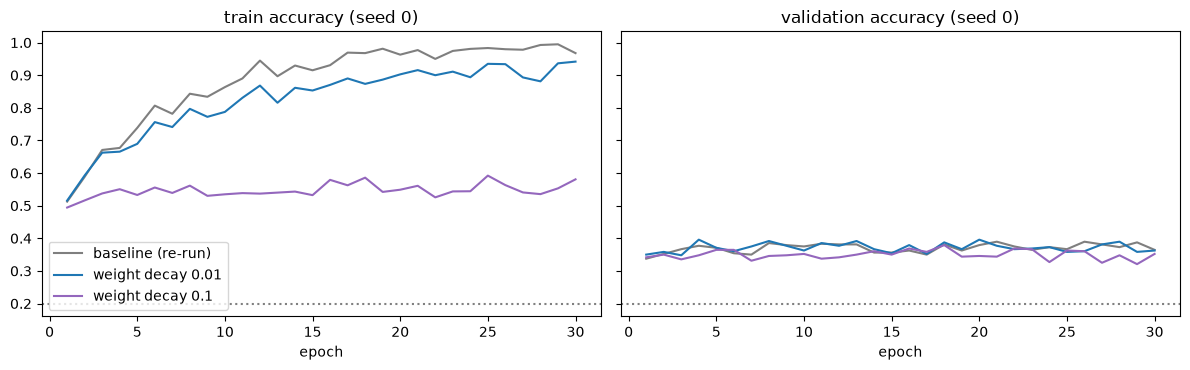

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for label, color in zip(["baseline (re-run)", "weight decay 0.01", "weight decay 0.1"], ["tab:grey", "tab:blue", "tab:purple"]):
    h = runs[label]["result"]["history"]
    axes[0].plot(range(1, 31), h["train_acc"], color=color, label=label)
    axes[1].plot(range(1, 31), h["val_acc"], color=color, label=label)
axes[0].set_title("train accuracy (seed 0)")
axes[1].set_title("validation accuracy (seed 0)")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.axhline(0.2, color="grey", linestyle=":")
axes[0].legend()
plt.tight_layout()
plt.show()

**What we see.**

- **The re-run baseline matches the record:** 39.0% over 5 seeds (std 0.8, 37.7% to 40.0%), the recorded P02 mean. The reference holds on this computer.
- **Weight decay narrows the gap, not the error.** From 1e-4 to 1e-2 the mean moves by +0.3 to +0.4 points (39.2% to 39.3%), far below the 2-point bar, and the network still ends at 94 to 95% train accuracy (seed 0). At 1e-1 the gap between train and validation falls from 60 to 23 points (seed 0, last epoch), but because train accuracy drops to 58%, not because validation rises: validation falls to 38.4%.
- So the overfitting can be removed, and validation does not follow. The memorised part was never helping on new paintings; what the network can generalise from flattened 32 px pixels stays at about 39%.

## 3. Dropout

During training, dropout sets a random share p of the hidden units to 0 at every step (and scales the others by 1 / (1 - p)),
so no unit can rely on another one being there. At evaluation every unit is used. Two values, 0.2 and 0.5, after the hidden
layer.

In [5]:
for p in [0.2, 0.5]:
    variant(f"dropout {p:g}", f"dense_dropout{p:g}", dropout=p)
verdict(["baseline (re-run)", "dropout 0.2", "dropout 0.5"])

===== dropout 0.2: {'dropout': 0.2}
393989 parameters | before training: loss 1.639 (ln 5 = 1.609), accuracy 16.4%
epoch   1 | train loss 1.192 acc 0.507 | val loss 1.562 acc 0.344


epoch   5 | train loss 0.826 acc 0.682 | val loss 1.559 acc 0.342
epoch  10 | train loss 0.577 acc 0.803 | val loss 1.782 acc 0.367


epoch  15 | train loss 0.426 acc 0.881 | val loss 2.090 acc 0.392
epoch  20 | train loss 0.236 acc 0.938 | val loss 2.200 acc 0.367


epoch  25 | train loss 0.169 acc 0.959 | val loss 2.384 acc 0.342
epoch  30 | train loss 0.125 acc 0.968 | val loss 2.638 acc 0.354

best validation accuracy 39.6% at epoch 6 (1 s)
seed 1 (1 of 4 more): training, about 1 s...


   best validation accuracy 39.2% at epoch 28
seed 2 (2 of 4 more): training, about 1 s...


...

   best validation accuracy 39.0% at epoch 17
seed 2 (2 of 4 more): training, about 1 s...


   best validation accuracy 39.0% at epoch 5
seed 3 (3 of 4 more): training, about 1 s...


   best validation accuracy 39.0% at epoch 19
seed 4 (4 of 4 more): training, about 1 s...


   best validation accuracy 39.6% at epoch 9
saved results/dense_dropout0.5_2026-10-26_18-21-39.pkl and added a row to results/experiments.csv
===== dropout 0.5: mean 39.2% (std 0.3%, 39.0% to 39.6%)



,val mean (5 seeds),std,min,max,gain over baseline,counts (> +2 points),"seed 0: train - val, last epoch"
variant,,,,,,,
baseline (re-run),0.390,0.008,0.377,0.400,0.000,False,0.603
dropout 0.2,0.393,0.005,0.390,0.400,0.004,False,0.614
dropout 0.5,0.392,0.003,0.390,0.396,0.002,False,0.540


**What we see.**

- **Dropout does not help either:** 39.3% (p = 0.2) and 39.2% (p = 0.5), +0.4 and +0.2 points. It makes the seeds more alike (std 0.5 and 0.3 against 0.8), but the mean stays where it was, and the train accuracy still ends 54 to 61 points above validation.

## 4. Input size, depth and learning rate

Three more single changes. **Smaller or larger images:** 16 px (768 numbers) gives fewer weights to memorise with, 64 px
(12,288 numbers) more detail but four times the weights of the first layer. **Two hidden layers** of 128 instead of one.
**Learning rate 1e-4:** the lead of P12, where one seed reached 40.0% and was still rising.

In [6]:
variant("16 px", "dense_16px", image_size=16)
variant("64 px", "dense_64px", image_size=64)
variant("2 hidden layers", "dense_2layers", hidden=[128, 128])
variant("learning rate 1e-4", "dense_lr1e-4", lr=1e-4)
verdict(["baseline (re-run)", "16 px", "64 px", "2 hidden layers", "learning rate 1e-4"])

===== 16 px: {'image_size': 16}


99077 parameters | before training: loss 1.622 (ln 5 = 1.609), accuracy 19.0%
epoch   1 | train loss 1.253 acc 0.484 | val loss 1.461 acc 0.331
epoch   5 | train loss 0.961 acc 0.634 | val loss 1.434 acc 0.369
epoch  10 | train loss 0.748 acc 0.742 | val loss 1.572 acc 0.360
epoch  15 | train loss 0.515 acc 0.852 | val loss 1.712 acc 0.367


epoch  20 | train loss 0.416 acc 0.882 | val loss 1.978 acc 0.354
epoch  25 | train loss 0.236 acc 0.956 | val loss 2.027 acc 0.365
epoch  30 | train loss 0.202 acc 0.953 | val loss 2.244 acc 0.373

best validation accuracy 39.2% at epoch 27 (0 s)
seed 1 (1 of 4 more): training, about 0 s...


   best validation accuracy 39.8% at epoch 16
seed 2 (2 of 4 more): training, about 0 s...


   best validation accuracy 39.2% at epoch 9
seed 3 (3 of 4 more): training, about 0 s...


...

   best validation accuracy 40.0% at epoch 21
seed 2 (2 of 4 more): training, about 1 s...


   best validation accuracy 38.1% at epoch 13
seed 3 (3 of 4 more): training, about 1 s...


   best validation accuracy 38.1% at epoch 25
seed 4 (4 of 4 more): training, about 1 s...


   best validation accuracy 39.0% at epoch 14
saved results/dense_lr1e-4_2026-10-26_18-22-05.pkl and added a row to results/experiments.csv
===== learning rate 1e-4: mean 39.0% (std 0.9%, 38.1% to 40.0%)



,val mean (5 seeds),std,min,max,gain over baseline,counts (> +2 points),"seed 0: train - val, last epoch"
variant,,,,,,,
baseline (re-run),0.390,0.008,0.377,0.400,0.000,False,0.603
16 px,0.391,0.006,0.381,0.398,0.002,False,0.580
64 px,0.390,0.006,0.385,0.400,0.000,False,0.610
2 hidden layers,0.402,0.003,0.398,0.404,0.013,False,0.607
learning rate 1e-4,0.390,0.009,0.381,0.400,0.001,False,0.501


**What we see.**

- **The input size does not matter:** 16 px (99k weights) 39.1%, 64 px (1.6 million weights) 39.0%. Four times fewer or four times more numbers per painting give the same score: the dense network uses only the coarse layout of colours, which 16 px already holds.
- **Two hidden layers: 40.2%,** +1.3 points, the most regular of all (std 0.3), but below the 2-point bar.
- **The lead of P12 does not hold:** at learning rate 1e-4, seed 0 again reaches 40.0%, but the 5-seed mean is 39.0%, exactly the baseline. One good seed was luck: the reason for the 5-seed rule.